**Level 1  (Task 1 ) - Data Exploration and preprocessing**

**Importing the libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

**Reading the dataset**

In [2]:
df=pd.read_csv("/content/Dataset .csv")

In [3]:
df

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9546,5915730,Naml۱ Gurme,208,��stanbul,"Kemanke�� Karamustafa Pa��a Mahallesi, R۱ht۱m ...",Karak�_y,"Karak�_y, ��stanbul",28.977392,41.022793,Turkish,...,Turkish Lira(TL),No,No,No,No,3,4.1,Green,Very Good,788
9547,5908749,Ceviz A��ac۱,208,��stanbul,"Ko��uyolu Mahallesi, Muhittin ��st�_nda�� Cadd...",Ko��uyolu,"Ko��uyolu, ��stanbul",29.041297,41.009847,"World Cuisine, Patisserie, Cafe",...,Turkish Lira(TL),No,No,No,No,3,4.2,Green,Very Good,1034
9548,5915807,Huqqa,208,��stanbul,"Kuru�_e��me Mahallesi, Muallim Naci Caddesi, N...",Kuru�_e��me,"Kuru�_e��me, ��stanbul",29.034640,41.055817,"Italian, World Cuisine",...,Turkish Lira(TL),No,No,No,No,4,3.7,Yellow,Good,661
9549,5916112,A���k Kahve,208,��stanbul,"Kuru�_e��me Mahallesi, Muallim Naci Caddesi, N...",Kuru�_e��me,"Kuru�_e��me, ��stanbul",29.036019,41.057979,Restaurant Cafe,...,Turkish Lira(TL),No,No,No,No,4,4.0,Green,Very Good,901


**checking the size of the dataset**

In [4]:
print("Number of rows:",df.shape[0])
print("Number of columns:",df.shape[1])

Number of rows: 9551
Number of columns: 21


**checking the missing values**

In [5]:
df.isna().sum()

,0
Restaurant ID,0
Restaurant Name,0
Country Code,0
City,0
Address,0
Locality,0
Locality Verbose,0
Longitude,0
Latitude,0
Cuisines,9


**Cuisines column has 9 missing values.so we will fill the missing values in cuisine by using unknown instead of deleting the restaurant records.**

In [6]:
df['Cuisines']=df["Cuisines"].fillna("Unknown")
print("Missing values after handling:",df['Cuisines'].isna().sum())

Missing values after handling: 0


**checking the datatypes**

In [7]:
df.dtypes

,0
Restaurant ID,int64
Restaurant Name,object
Country Code,int64
City,object
Address,object
Locality,object
Locality Verbose,object
Longitude,float64
Latitude,float64
Cuisines,object


**Analyzing Aggregate rating distribution**

Aggregate rating
0.0    2148
1.8       1
1.9       2
2.0       7
2.1      15
2.2      27
2.3      47
2.4      87
2.5     110
2.6     191
2.7     250
2.8     315
2.9     381
3.0     468
3.1     519
3.2     522
3.3     483
3.4     498
3.5     480
3.6     458
3.7     427
3.8     400
3.9     335
4.0     266
4.1     274
4.2     221
4.3     174
4.4     144
4.5      95
4.6      78
4.7      42
4.8      25
4.9      61
Name: count, dtype: int64


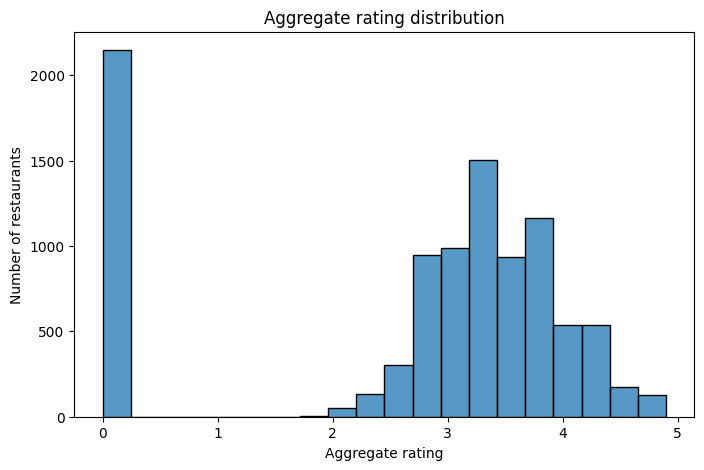

In [8]:
print(df['Aggregate rating'].value_counts().sort_index())
plt.figure(figsize=(8,5))
sns.histplot(x='Aggregate rating',data=df,bins=20)
plt.title("Aggregate rating distribution")
plt.xlabel("Aggregate rating")
plt.ylabel("Number of restaurants")
plt.show()


- Rating 0.0: There is a large group of restaurants with a rating of zero. In this dataset, these generally represent restaurants without a recorded rating, rather than a poor rating.
- Ratings between 3.0 and 4.0: Many restaurants fall within this range.
- Ratings above 4.0: Fewer restaurants have these higher ratings compared with the main group.

**check the ratings count**

In [9]:
print("Restaurants with 0 ratings:",(df["Aggregate rating"]==0).sum())
print("Restaurants with ratings above 0:",(df["Aggregate rating"]>0).sum())

Restaurants with 0 ratings: 2148
Restaurants with ratings above 0: 7403


**Level 1 (Task 2) - Descriptive analysis**

**calculating the basic statistical measures**

In [10]:
df.describe()

,Restaurant ID,Country Code,Longitude,Latitude,Average Cost for two,Price range,Aggregate rating,Votes
count,9.551000e+03,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000
mean,9.051128e+06,18.365616,64.126574,25.854381,1199.210763,1.804837,2.666370,156.909748
std,8.791521e+06,56.750546,41.467058,11.007935,16121.183073,0.905609,1.516378,430.169145
min,5.300000e+01,1.000000,-157.948486,-41.330428,0.000000,1.000000,0.000000,0.000000
25%,3.019625e+05,1.000000,77.081343,28.478713,250.000000,1.000000,2.500000,5.000000
50%,6.004089e+06,1.000000,77.191964,28.570469,400.000000,2.000000,3.200000,31.000000
75%,1.835229e+07,1.000000,77.282006,28.642758,700.000000,2.000000,3.700000,131.000000
max,1.850065e+07,216.000000,174.832089,55.976980,800000.000000,4.000000,4.900000,10934.000000


**checking the distribution of categorical variables Country code , city and cuisines.**

In [11]:
df['Cuisines'].value_counts()

,count
Cuisines,
North Indian,936
"North Indian, Chinese",511
Fast Food,354
Chinese,354
"North Indian, Mughlai",334
...,...
"North Indian, Continental, Chinese, Italian, Mexican",1
"North Indian, Continental, Chinese, Mexican, Italian, Desserts",1
"Southern, Cajun, Soul Food",1


In [12]:
df['Cuisines'].value_counts().head(10)

,count
Cuisines,
North Indian,936
"North Indian, Chinese",511
Fast Food,354
Chinese,354
"North Indian, Mughlai",334
Cafe,299
Bakery,218
"North Indian, Mughlai, Chinese",197
"Bakery, Desserts",170


- North Indian is the most frequent cuisine entry, with 936 restaurants.
- North Indian, Chinese comes second, with 511 restaurants.
- Fast Food and Chinese each have 354 restaurants.
- North Indian, Mughlai has 334 restaurants.

In [13]:
df['City'].value_counts().head(10)

,count
City,
New Delhi,5473
Gurgaon,1118
Noida,1080
Faridabad,251
Ghaziabad,25
Bhubaneshwar,21
Lucknow,21
Ahmedabad,21
Amritsar,21


New Delhi has the highest number of restaurant records: 5,473.
Gurgaon comes second with 1,118.
Noida comes third with 1,080.
Faridabad has 251 restaurant records.

In [14]:
df['Country Code'].value_counts()

,count
Country Code,
1,8652
216,434
215,80
30,60
189,60
214,60
148,40
208,34
14,24


Country Code 1 has the highest number of restaurant records: 8,652.



Country Code 216 has 434 records.



Country Codes 215, 30, 189, and 214 have 80, 60, 60, and 60 records, respectively.



The dataset contains restaurant records from 15 distinct country codes.

**Top cuisines and cities with highest number of restaurants**

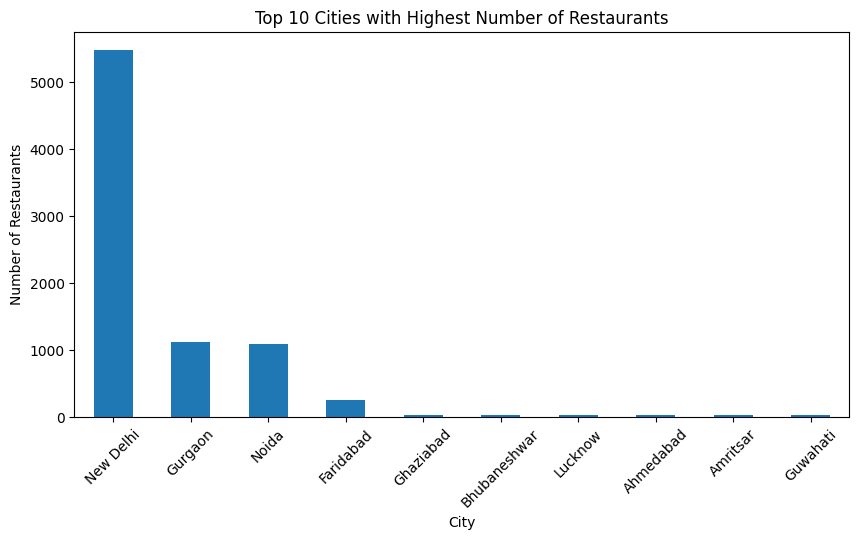

In [15]:
top_cities=df['City'].value_counts().head(10)
plt.figure(figsize=(10,5))
top_cities.plot(kind="bar")
plt.title("Top 10 Cities with Highest Number of Restaurants")
plt.xlabel("City")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=45)
plt.show()

New Delhi has the highest number of restaurants (5,473).
Gurgaon has 1,118, followed by Noida with 1,080.
The remaining cities have considerably fewer restaurants in this dataset.

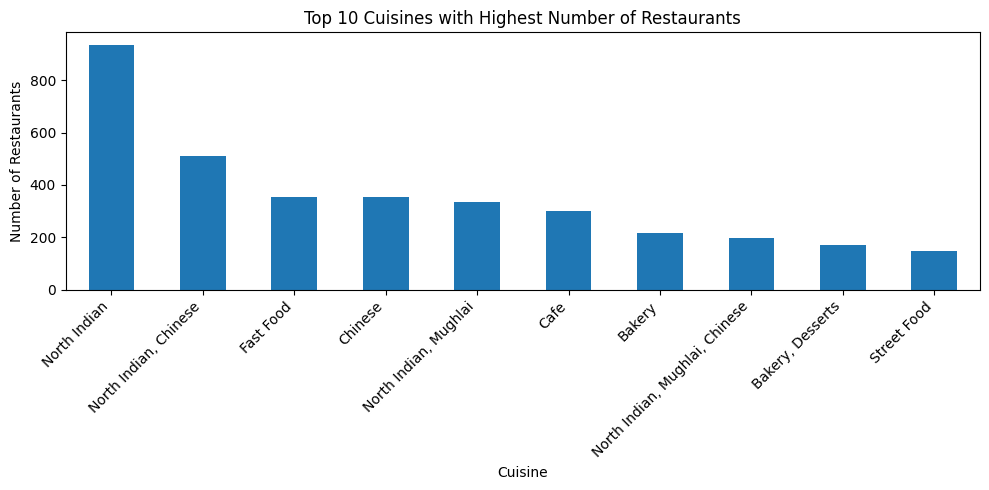

In [16]:
top_cuisines=df['Cuisines'].value_counts().head(10)
plt.figure(figsize=(10,5))
top_cuisines.plot(kind="bar")
plt.title("Top 10 Cuisines with Highest Number of Restaurants")
plt.xlabel("Cuisine")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

North Indian is the most common cuisine entry, with 936 restaurants.
North Indian, Chinese comes second, with 511
Fast Food and Chinese each have 354.
North Indian, Mughlai has 334.

**Descriptive Analysis conclusion**

The descriptive analysis was performed on the restaurant dataset containing 9,551 records and 21 columns. Statistical measures such as mean, median, standard deviation, minimum, and maximum were calculated for numerical columns. The categorical analysis showed that Country Code 1 had the highest number of restaurant records, while New Delhi was the city with the most restaurants, with 5,473 records. North Indian was the most frequent cuisine entry, appearing 936 times. Bar charts were created to visualize the top cities and cuisines.

**Level 1 (Task 3) - Geospatial Analysis**

In [17]:
import plotly.express as px
map_df=df.dropna(subset=['Latitude','Longitude'])
fig=px.scatter_geo(map_df,lat="Latitude",lon="Longitude",hover_name="Restaurant Name",color="Aggregate rating",title="Geographical Distribution of Restaurants",projection="natural earth")
fig.show()


**Restaurant distribution across cities**

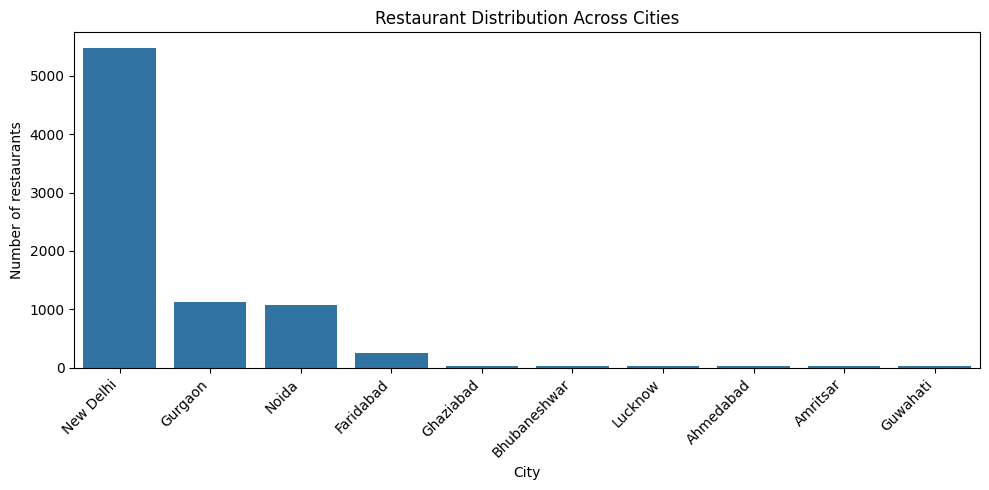

In [18]:
city_counts=df['City'].value_counts().head(10)
plt.figure(figsize=(10,5))
sns.barplot(x=city_counts.index,y=city_counts.values)
plt.title("Restaurant Distribution Across Cities")
plt.xlabel("City")
plt.ylabel("Number of restaurants")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

**Analyzing there is any correlation between Location and rating**

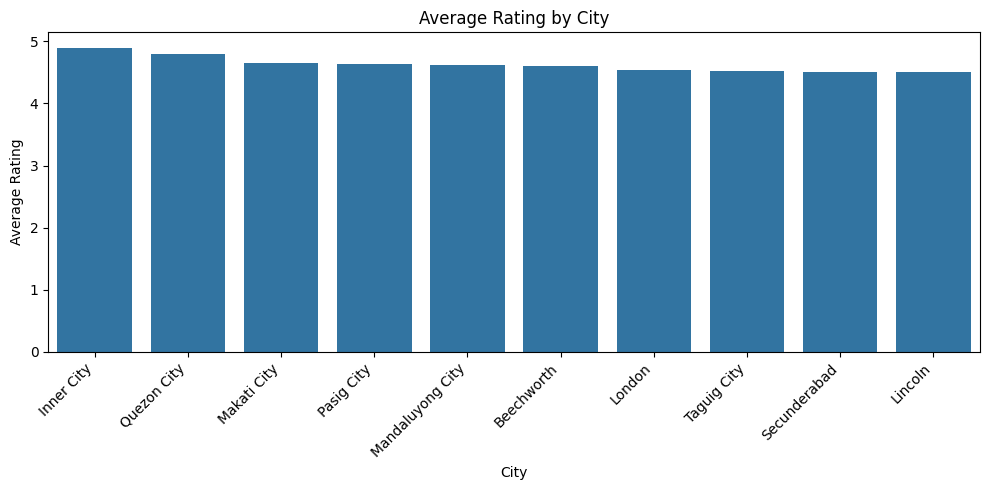

In [19]:
city_rating=df.groupby('City')['Aggregate rating'].mean().sort_values(ascending=False).head(10)
plt.figure(figsize=(10,5))
sns.barplot(x=city_rating.index,y=city_rating.values)
plt.title("Average Rating by City")
plt.xlabel("City")
plt.ylabel("Average Rating")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

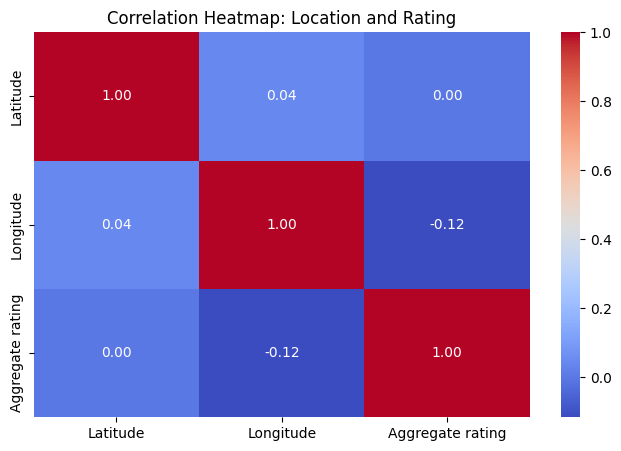

In [20]:
correlation = df[["Latitude", "Longitude", "Aggregate rating"]].corr()
plt.figure(figsize=(8, 5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap: Location and Rating")
plt.show()


The correlation heatmap shows that latitude has almost no linear relationship with restaurant ratings, while longitude has a very weak negative correlation of -0.12. This suggests that restaurant ratings are not strongly associated with latitude or longitude in this dataset.

**Level 2 (Task 1)** -**percentage of restaurants that offer table booking and online delivery.**

In [21]:
print("Table booking:")
print(df['Has Table booking'].value_counts())
print("\nOnline delivery:")
print(df['Has Online delivery'].value_counts())

Table booking:
Has Table booking
No     8393
Yes    1158
Name: count, dtype: int64

Online delivery:
Has Online delivery
No     7100
Yes    2451
Name: count, dtype: int64


**calculating the percentages**

In [22]:
total=len(df)
table_booking=(df['Has Table booking'].value_counts(normalize=True)*100)
online_delivery=(df['Has Online delivery'].value_counts(normalize=True)*100)
print("Percentage of restaurants that offer table booking:")
print(table_booking)
print("\nPercentage of restaurants that offer online delivery:")
print(online_delivery)

Percentage of restaurants that offer table booking:
Has Table booking
No     87.875615
Yes    12.124385
Name: proportion, dtype: float64

Percentage of restaurants that offer online delivery:
Has Online delivery
No     74.337766
Yes    25.662234
Name: proportion, dtype: float64


**Comparing the average ratings with and without table booking**

Has Table booking
No     2.559359
Yes    3.441969
Name: Aggregate rating, dtype: float64


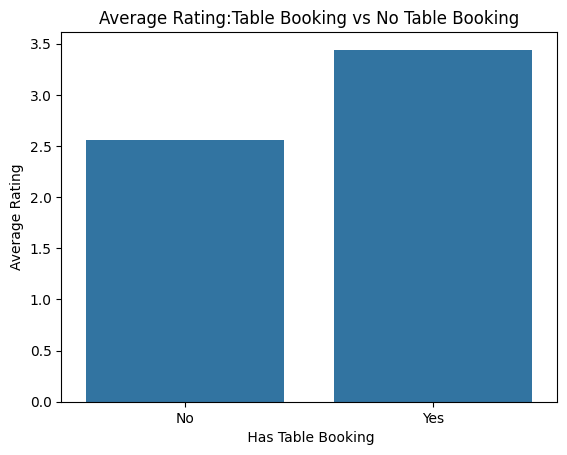

In [23]:
booking_rating=df.groupby('Has Table booking')['Aggregate rating'].mean()
print(booking_rating)
sns.barplot(x=booking_rating.index,y=booking_rating.values)
plt.title("Average Rating:Table Booking vs No Table Booking")
plt.xlabel(" Has Table Booking")
plt.ylabel("Average Rating")
plt.show()

**Restaurants that offer table booking have a higher average rating than restaurants that do not offer table booking. The average rating is approximately 3.44 for restaurants with table booking and 2.56 for restaurants without table booking. This suggests an association between table booking availability and higher restaurant ratings, but it does not prove that table booking causes higher ratings.**

**Analyzing the online delivery by price range**

Has Online delivery         No        Yes
Price range                              
1                    84.225923  15.774077
2                    58.689367  41.310633
3                    70.809659  29.190341
4                    90.955631   9.044369


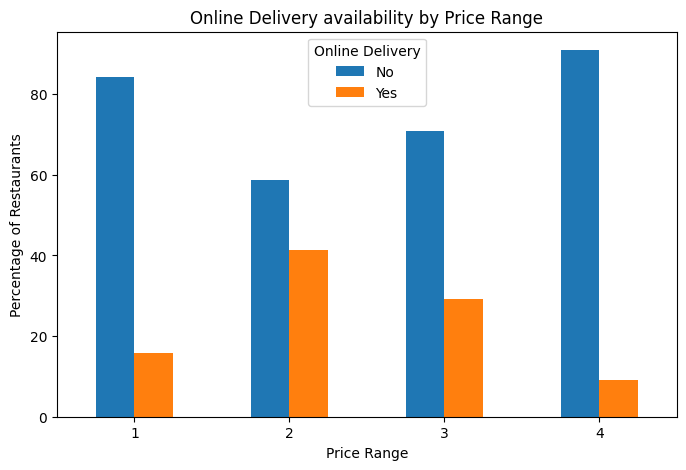

In [24]:
delivery_price=pd.crosstab(df['Price range'],df['Has Online delivery'],normalize="index")*100
print(delivery_price)
delivery_price.plot(kind="bar",figsize=(8,5))
plt.title("Online Delivery availability by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Percentage of Restaurants")
plt.xticks(rotation=0)
plt.legend(title="Online Delivery")
plt.show()

**The analysis shows that online delivery availability varies across price ranges. Restaurants in Price Range 2 have the highest percentage of online delivery availability, at approximately 41%, while Price Range 4 has the lowest, at approximately 9%. This suggests that online delivery is more common among restaurants in the lower-to-middle price ranges than among the most expensive restaurants in this dataset.**

**Level 2 (Task 2)** **-** **Find the most common price range**

In [25]:
df['Price range'].value_counts()

,count
Price range,
1,4444
2,3113
3,1408
4,586


**Calculating the average rating for each price range**

In [26]:
price_rating=df.groupby('Price range')['Aggregate rating'].mean()
print(price_rating)

Price range
1    1.999887
2    2.941054
3    3.683381
4    3.817918
Name: Aggregate rating, dtype: float64


**Price Range 4 has the highest average rating of approximately 3.82, while Price Range 1 has the lowest average rating of approximately 2.00.**

**Identifying the color representing the highest average rating**

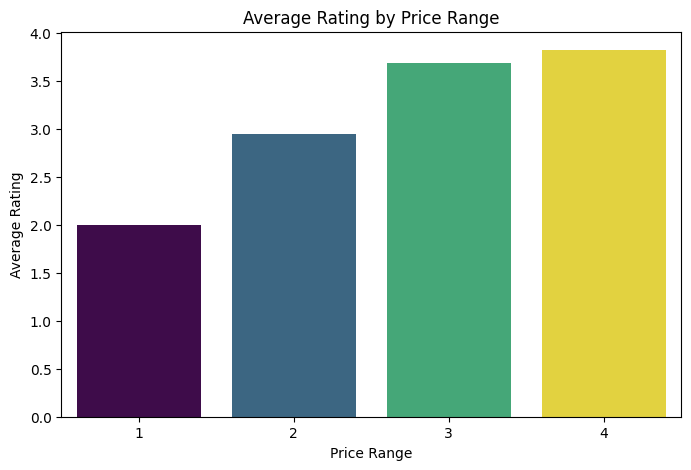

In [27]:
plt.figure(figsize=(8,5))
sns.barplot(x=price_rating.index,y=price_rating.values,hue=price_rating.index,palette="viridis",legend=False)
plt.title("Average Rating by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Average Rating")
plt.show()

In [28]:
print("\nMost common rating color in each price range:")
print(df.groupby('Price range')['Rating color'].agg(lambda x: x.mode()[0]))


Most common rating color in each price range:
Price range
1    Orange
2    Orange
3    Yellow
4    Yellow
Name: Rating color, dtype: object


In [29]:
df['Rating color'].value_counts()

,count
Rating color,
Orange,3737
White,2148
Yellow,2100
Green,1079
Dark Green,301
Red,186


In [30]:
color_rating=df.groupby('Rating color')['Aggregate rating'].mean()
print("\n Average rating for each rating color:")
print(color_rating.sort_values(ascending=False))
print("\nRating color with the highest average rating:")
print(color_rating.idxmax())



 Average rating for each rating color:
Rating color
Dark Green    4.659801
Green         4.168119
Yellow        3.683429
Orange        3.051619
Red           2.297849
White         0.000000
Name: Aggregate rating, dtype: float64

Rating color with the highest average rating:
Dark Green


**The analysis shows that Price Range 4 has the highest average restaurant rating of approximately 3.82. When grouped by rating color, Dark Green has the highest average rating of approximately 4.66, followed by Green at 4.17. This indicates that higher rating colors are associated with better restaurant ratings in the dataset.**

**Level 2 (Task 3) -** **feature Engineering**

**Creating new Features**

In [31]:
df["Restaurant Name Length"]=df["Restaurant Name"].str.len()
df["Address Length"]=df["Address"].str.len()
print(df[["Restaurant Name","Restaurant Name Length","Address","Address Length"]].head())

          Restaurant Name  Restaurant Name Length  \
0        Le Petit Souffle                      16   
1        Izakaya Kikufuji                      16   
2  Heat - Edsa Shangri-La                      22   
3                    Ooma                       4   
4             Sambo Kojin                      11   

                                             Address  Address Length  
0  Third Floor, Century City Mall, Kalayaan Avenu...              71  
1  Little Tokyo, 2277 Chino Roces Avenue, Legaspi...              67  
2  Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...              56  
3  Third Floor, Mega Fashion Hall, SM Megamall, O...              70  
4  Third Floor, Mega Atrium, SM Megamall, Ortigas...              64  


**Encode categorical variables**

In [32]:
df["Has Table booking"] = df["Has Table booking"].map({"Yes": 1, "No": 0})
df["Has Online delivery"] = df["Has Online delivery"].map({"Yes": 1, "No": 0})
print(df[["Has Table booking", "Has Online delivery"]].head())

   Has Table booking  Has Online delivery
0                  1                    0
1                  1                    0
2                  1                    0
3                  0                    0
4                  1                    0


In [33]:
print(df[[
    "Restaurant Name Length",
    "Address Length",
    "Has Table booking",
    "Has Online delivery"
]].head())

print("\nDataset shape:", df.shape)


   Restaurant Name Length  Address Length  Has Table booking  \
0                      16              71                  1   
1                      16              67                  1   
2                      22              56                  1   
3                       4              70                  0   
4                      11              64                  1   

   Has Online delivery  
0                    0  
1                    0  
2                    0  
3                    0  
4                    0  

Dataset shape: (9551, 23)


**Level 3 (Task 1) -** **Predictive Model**

In [34]:
X = df.drop(
    columns=["Aggregate rating", "Rating color", "Rating text",
             "Restaurant ID"],
    errors="ignore"
)

y = df["Aggregate rating"]
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = X.select_dtypes(include=["object"]).columns
print("Numerical columns:")
print(list(numerical_cols))
print("\nCategorical columns:")
print(list(categorical_cols))
print("\nTotal input features:", X.shape[1])

Numerical columns:
['Country Code', 'Longitude', 'Latitude', 'Average Cost for two', 'Has Table booking', 'Has Online delivery', 'Price range', 'Votes', 'Restaurant Name Length', 'Address Length']

Categorical columns:
['Restaurant Name', 'City', 'Address', 'Locality', 'Locality Verbose', 'Cuisines', 'Currency', 'Is delivering now', 'Switch to order menu']

Total input features: 19


**Preparing the categorical columns**

In [35]:
categorical_features = ["City", "Cuisines", "Currency"]
selected_features = list(numerical_cols) + categorical_features
X = df[selected_features].copy()
y = df["Aggregate rating"]
print("Selected features:")
print(X.columns.tolist())
print("\nFeature shape:", X.shape)

Selected features:
['Country Code', 'Longitude', 'Latitude', 'Average Cost for two', 'Has Table booking', 'Has Online delivery', 'Price range', 'Votes', 'Restaurant Name Length', 'Address Length', 'City', 'Cuisines', 'Currency']

Feature shape: (9551, 13)


**Applying Frequency Enoding**

**splitting the data**

In [36]:
city_frequency = X["City"].value_counts(normalize=True)
X["City"] = X["City"].map(city_frequency)
cuisine_frequency = X["Cuisines"].value_counts(normalize=True)
X["Cuisines"] = X["Cuisines"].map(cuisine_frequency)
print(X[["City", "Cuisines"]].head())
print("\nShape after encoding:", X.shape)

       City  Cuisines
0  0.000209  0.000105
1  0.000209  0.001780
2  0.000419  0.000105
3  0.000419  0.001885
4  0.000419  0.000314

Shape after encoding: (9551, 13)


**Enoding Currency column**

In [37]:
X = pd.get_dummies(X, columns=["Currency"], dtype=int)

print("Shape after encoding:", X.shape)
print(X.head())

Shape after encoding: (9551, 24)
   Country Code   Longitude   Latitude  Average Cost for two  \
0           162  121.027535  14.565443                  1100   
1           162  121.014101  14.553708                  1200   
2           162  121.056831  14.581404                  4000   
3           162  121.056475  14.585318                  1500   
4           162  121.057508  14.584450                  1500   

   Has Table booking  Has Online delivery  Price range  Votes  \
0                  1                    0            3    314   
1                  1                    0            3    591   
2                  1                    0            4    270   
3                  0                    0            4    365   
4                  1                    0            4    229   

   Restaurant Name Length  Address Length  ...  Currency_Dollar($)  \
0                      16              71  ...                   0   
1                      16              67  ...     

In [38]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (7640, 24)
Testing data: (1911, 24)


**Linear Regression**

In [39]:
from sklearn.linear_model import LinearRegression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred=lr_model.predict(X_test)
print("Linear Regression model trained successfully")

Linear Regression model trained successfully


In [40]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Mean Absolute Error: 1.0206291077307736
Mean Squared Error: 1.536825081093106
Root Mean Squared Error: 1.2396874933196294
R2 Score: 0.32480162960731374


**Decision Tree model**

In [41]:
from sklearn.tree import DecisionTreeRegressor
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)
print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [42]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
r2_dt = r2_score(y_test, y_pred_dt)
print("Decision Tree Results")
print("MAE:", mae_dt)
print("MSE:", mse_dt)
print("RMSE:", rmse_dt)
print("R2 Score:", r2_dt)

Decision Tree Results
MAE: 0.2894819466248038
MSE: 0.1979068550497122
RMSE: 0.4448672330591591
R2 Score: 0.9130503609922463


**Random Forest**

In [43]:
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(n_estimators=100,random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)
print("Random Forest Results")
print("MAE:", mae_rf)
print("MSE:", mse_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Random Forest Results
MAE: 0.19639089481946626
MSE: 0.09109232182103609
RMSE: 0.30181504571680334
R2 Score: 0.9599789279824205


**Comparing all three models**

In [45]:
import pandas as pd
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [mae, mae_dt, mae_rf],
    "RMSE": [rmse, rmse_dt, rmse_rf],
    "R2 Score": [r2, r2_dt, r2_rf]
})
print(results)

               Model       MAE      RMSE  R2 Score
0  Linear Regression  1.020629  1.239687  0.324802
1      Decision Tree  0.289482  0.444867  0.913050
2      Random Forest  0.196391  0.301815  0.959979


**Random Forest is the best-performing model among the three tested models. Its R² score is approximately 96%, and its MAE is approximately 0.196 rating points.**

**Selecting the 10 most important features**

In [46]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance", ascending=False
)

print(importance.head(10))

                   Feature  Importance
7                    Votes    0.944038
10                    City    0.014697
1                Longitude    0.008517
2                 Latitude    0.007543
9           Address Length    0.006168
3     Average Cost for two    0.005822
11                Cuisines    0.005447
8   Restaurant Name Length    0.004922
5      Has Online delivery    0.000839
6              Price range    0.000779


In [47]:
# Select 5 restaurants from the test dataset
sample_data = X_test.head(5)

# Predict their ratings
predicted_ratings = rf_model.predict(sample_data)

# Display actual and predicted ratings
comparison = pd.DataFrame({
    "Actual Rating": y_test.head(5).values,
    "Predicted Rating": predicted_ratings
})

print(comparison.round(2))

   Actual Rating  Predicted Rating
0            2.1              3.28
1            4.1              3.34
2            3.2              2.87
3            4.4              3.78
4            3.5              3.02


**Saving the Trained Random Forest model**

In [48]:
import joblib
joblib.dump(rf_model, "restaurant_rating_model.pkl")
print("Model saved successfully")

Model saved successfully


In [49]:
from google.colab import files
files.download("restaurant_rating_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [50]:
import joblib

mappings = {
    "city": city_frequency.to_dict(),
    "cuisines": cuisine_frequency.to_dict()
}

joblib.dump(mappings, "frequency_mappings.pkl")

from google.colab import files
files.download("frequency_mappings.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:
# Get the original restaurant row
row = df[df["Restaurant Name"].str.strip() == "Le Petit Souffle"].iloc[0]

# Build the model input from the original dataset
test_input = pd.DataFrame([{
    "Country Code": row["Country Code"],
    "Longitude": row["Longitude"],
    "Latitude": row["Latitude"],
    "Average Cost for two": row["Average Cost for two"],
    "Has Table booking": row["Has Table booking"],
    "Has Online delivery": row["Has Online delivery"],
    "Price range": row["Price range"],
    "Votes": row["Votes"],
    "Restaurant Name Length": row["Restaurant Name Length"],
    "Address Length": row["Address Length"],
    "City": city_frequency.get(row["City"], 0.0),
    "Cuisines": cuisine_frequency.get(row["Cuisines"], 0.0)
}])

# Add currency encoding
for col in X.columns:
    if col.startswith("Currency_"):
        test_input[col] = int(col == "Currency_" + row["Currency"])

# Match the training feature order
test_input = test_input.reindex(columns=X.columns, fill_value=0)

# Predict
print("Actual rating:", row["Aggregate rating"])
print("Prediction from original row:", rf_model.predict(test_input)[0])

Actual rating: 4.8
Prediction from original row: 4.321999999999996
